In [15]:
# 1) Loading the Taxis Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [16]:
# 2) Handling Missing Values
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [17]:
# Display columns that contain missing values
df.isnull().sum()[df.isnull().sum() > 0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [19]:
# Fill missing payment values with mode
df['payment']=df['payment'].fillna(df['payment'].mode()[0])
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment             0
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [20]:
df.dropna(subset=['pickup_zone','dropoff_zone','pickup_borough','dropoff_borough'],inplace=True)

In [21]:
# Check missing values again
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

# 3) Visualizations using Matplotlib/Pandas Plot:

#### Line Chart


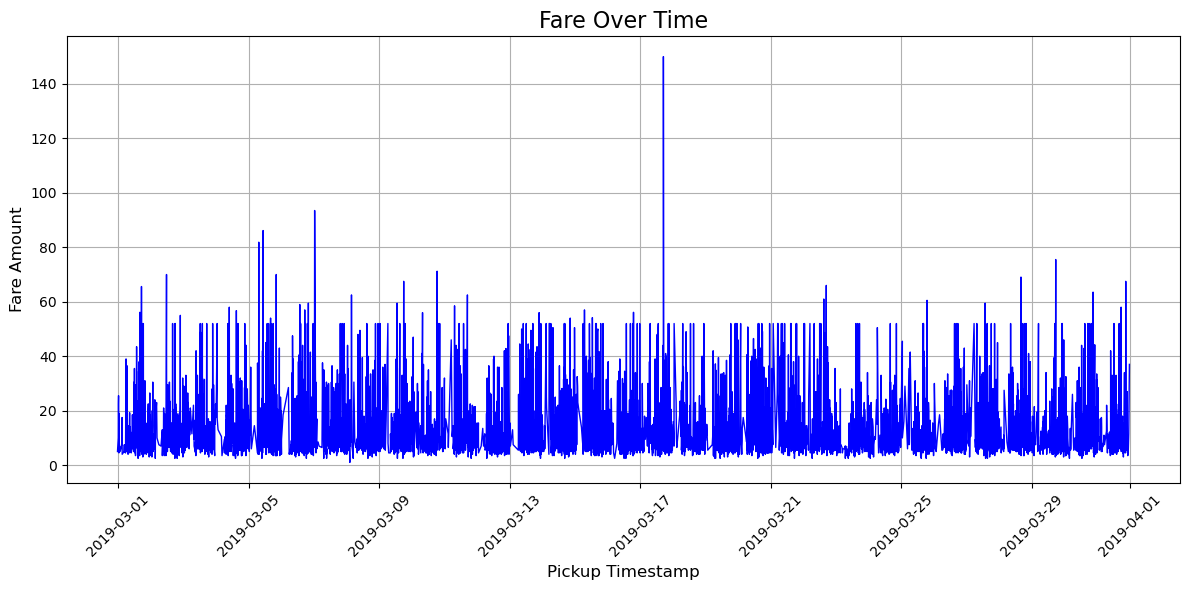

In [22]:
# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort the dataset by pickup timestamp
df = df.sort_values(by='pickup')

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'], color='blue', linewidth=1)

# Add title and labels
plt.title('Fare Over Time', fontsize=16)
plt.xlabel('Pickup Timestamp', fontsize=12)
plt.ylabel('Fare Amount', fontsize=12)

# Rotate x-axis labels
plt.xticks(rotation=45)

# Display grid
plt.grid(True)

# Display chart
plt.tight_layout()
plt.show()

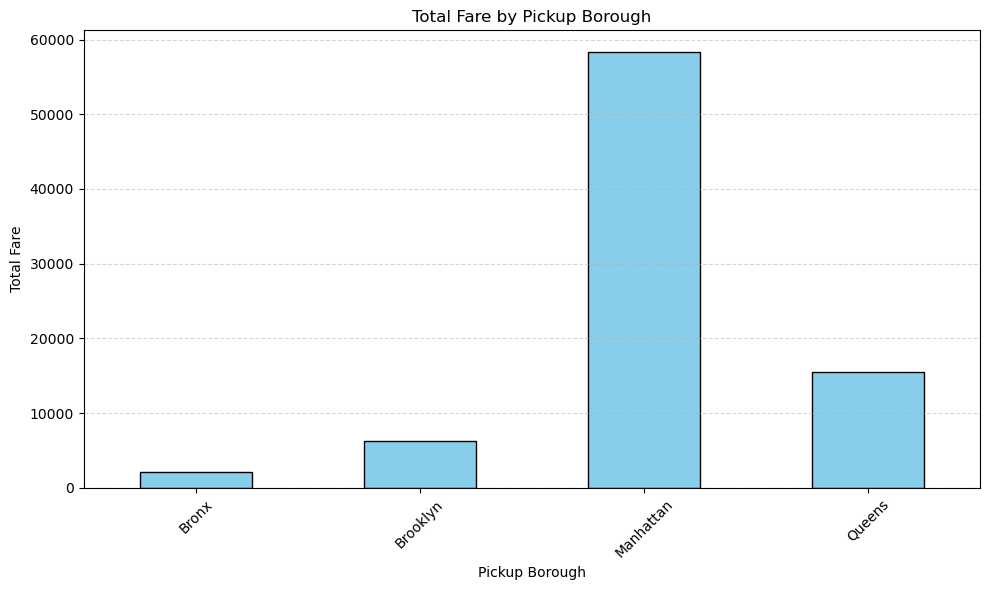

In [23]:
# Group data by pickup_borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 6))
borough_fare.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

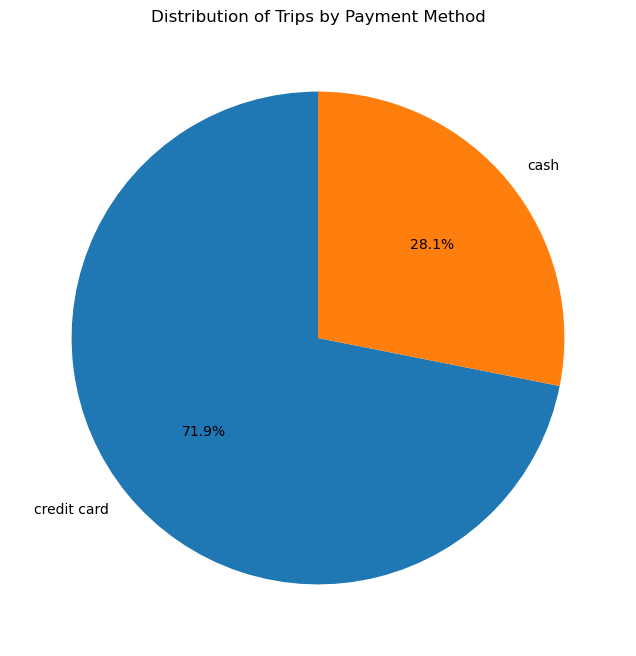

In [24]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        shadow=False)

plt.title('Distribution of Trips by Payment Method')

plt.show()

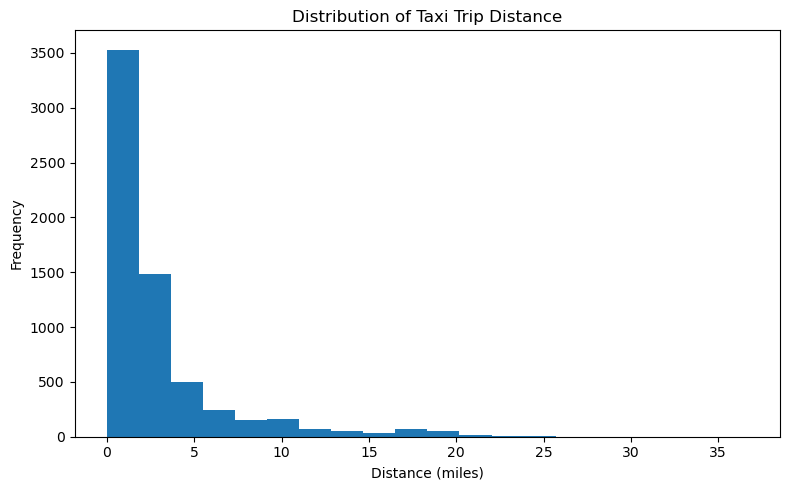

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(df['distance'], bins=20)

plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.title('Distribution of Taxi Trip Distance')

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

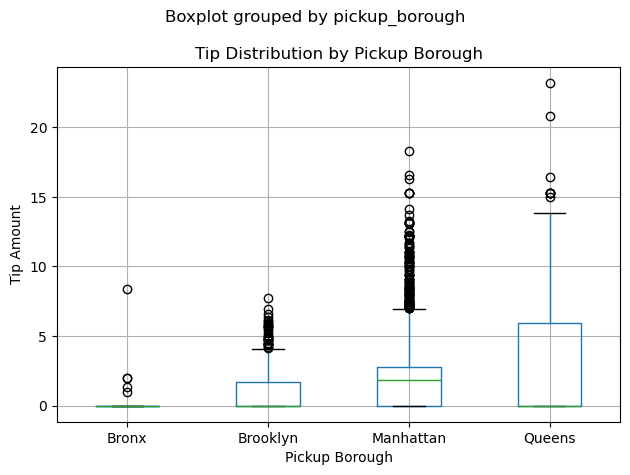

In [28]:
# Create box plot
plt.figure(figsize=(10, 6))

df.boxplot(column='tip',
           by='pickup_borough')

plt.title('Tip Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.tight_layout()
plt.show()

# Visualizations using Seaborn:

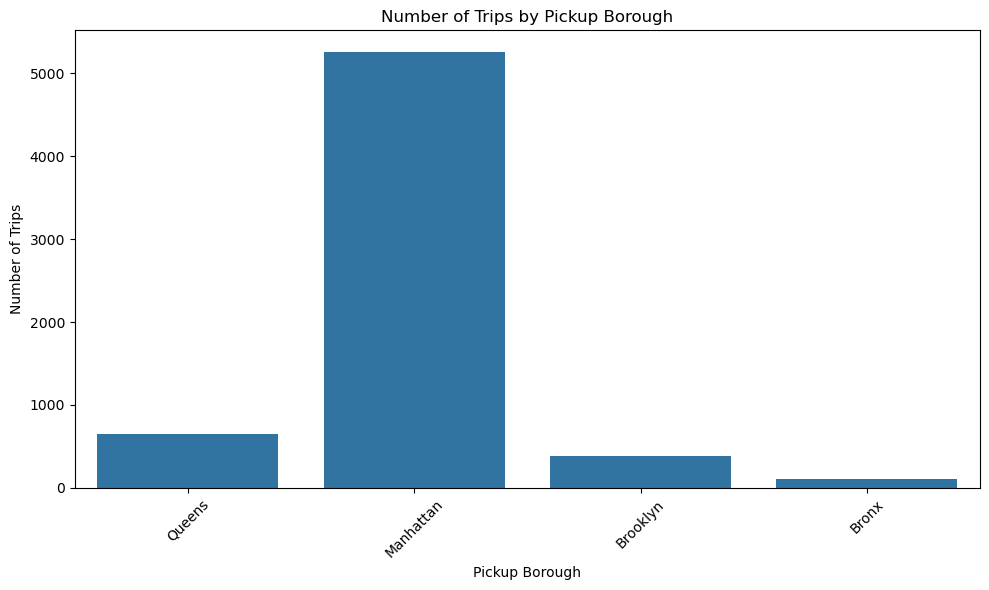

In [30]:
# Count Plot
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by Pickup Borough')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

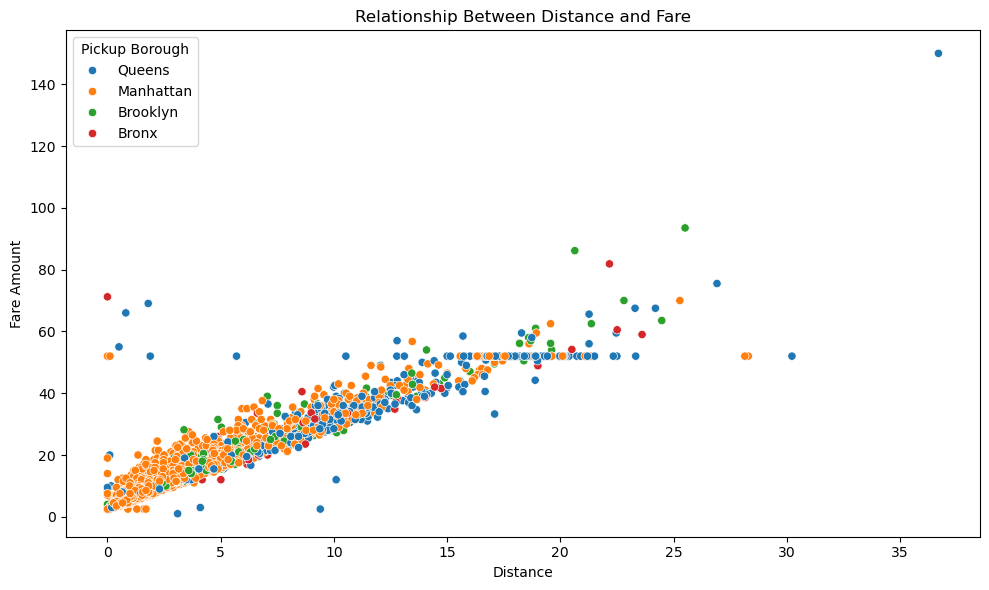

In [32]:
# Scatter Plot – Distance vs Fare

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df,
                x='distance',
                y='fare',
                hue='pickup_borough')

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare Amount')
plt.legend(title='Pickup Borough')

plt.tight_layout()
plt.show()

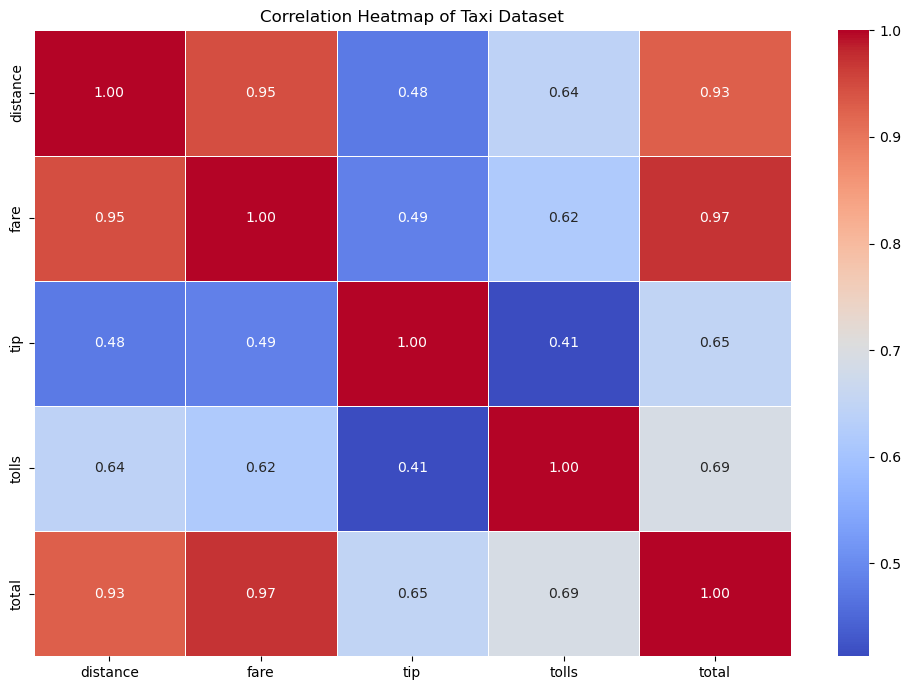

In [34]:
# Heatmap – Correlation Between Numerical Variables
# Select numerical columns
numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5)

plt.title('Correlation Heatmap of Taxi Dataset')

plt.tight_layout()
plt.show()

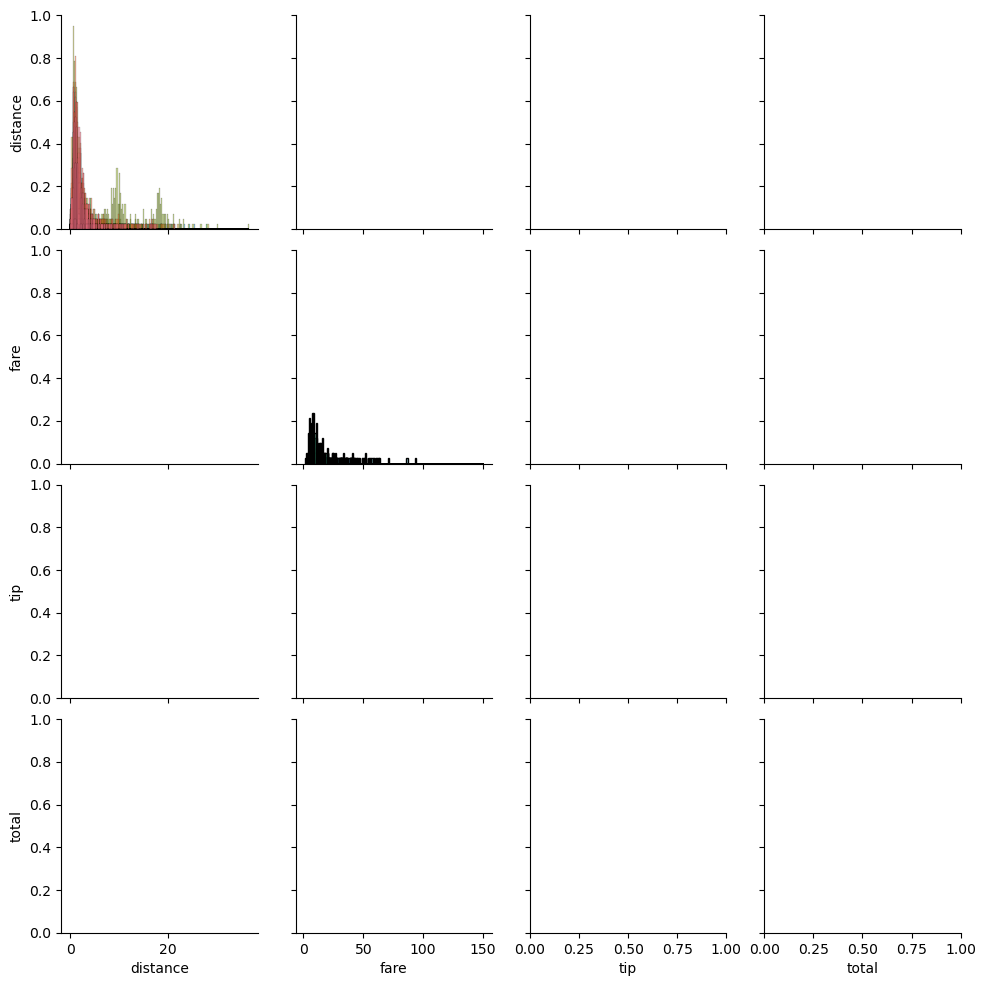

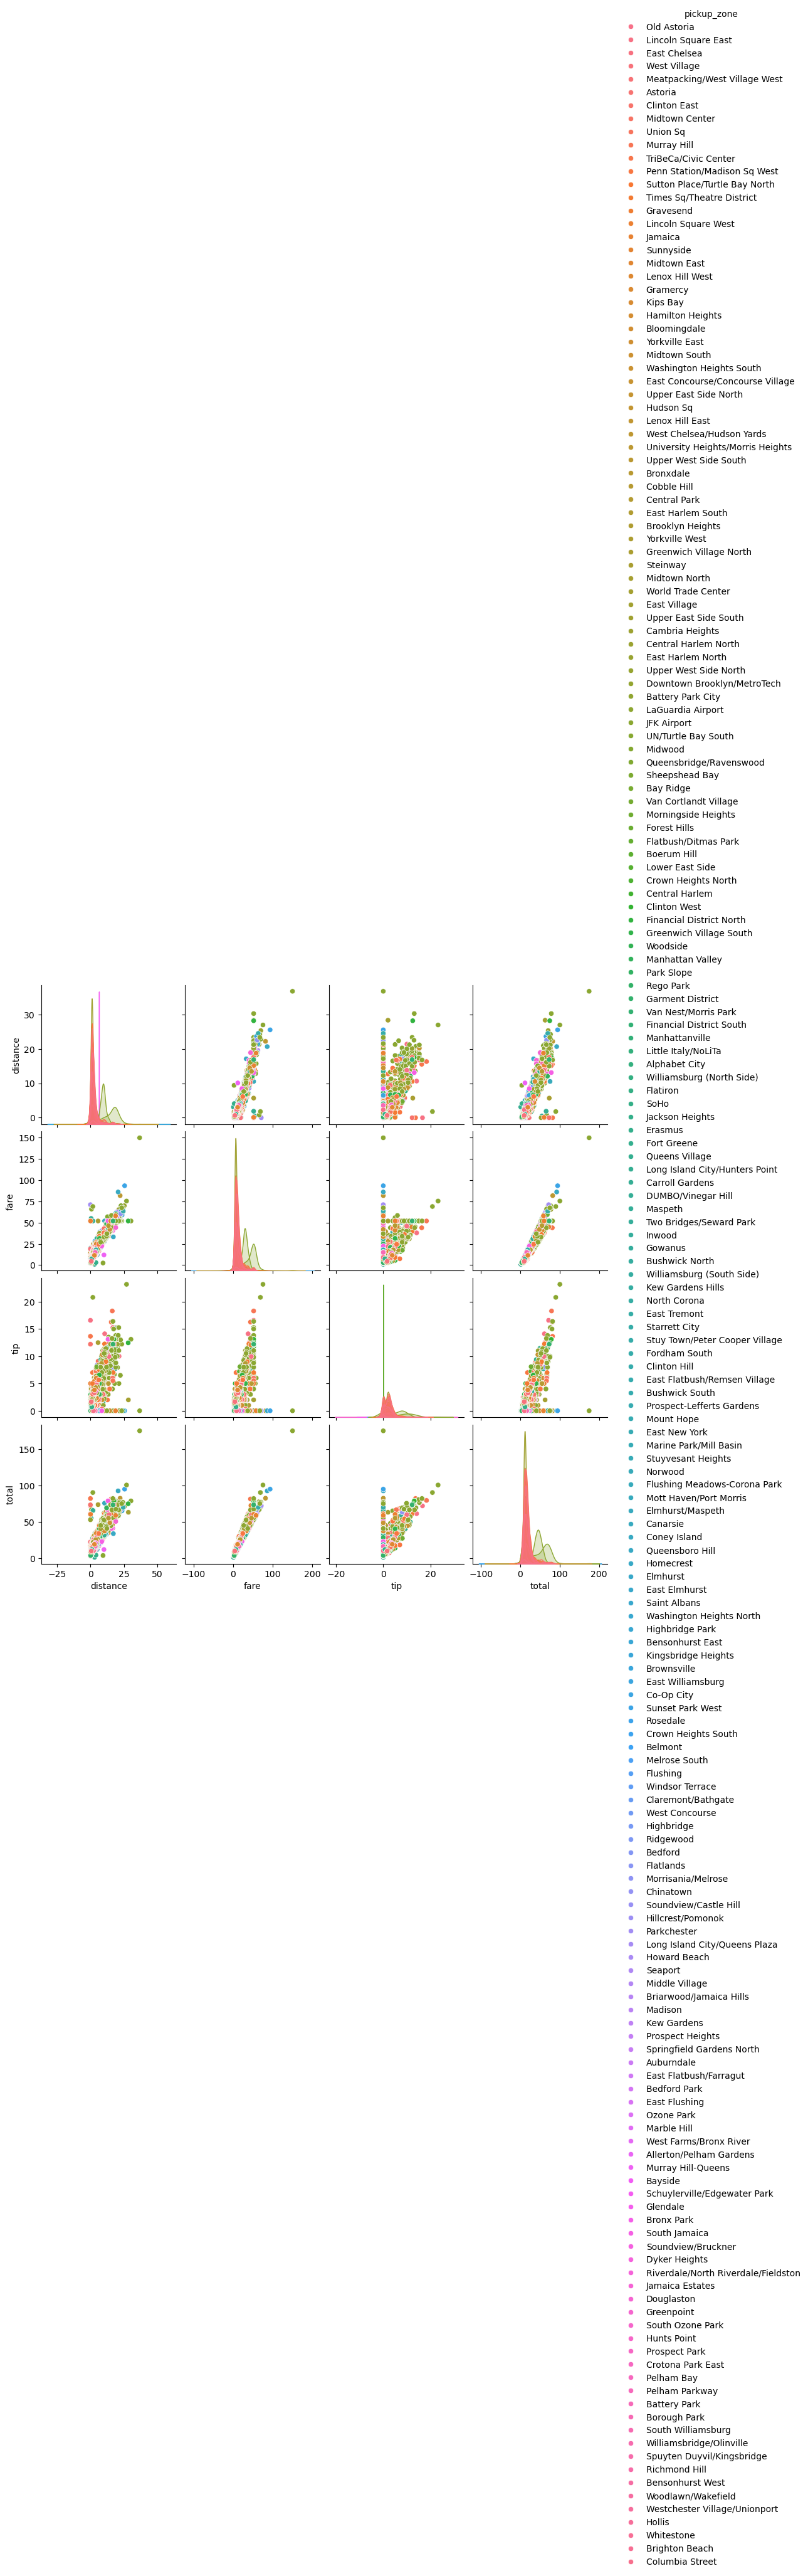

In [37]:
# Pair Plot – Pairwise Relationships
pair_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()

# Create pair plot
sns.pairplot(
    pair_df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()

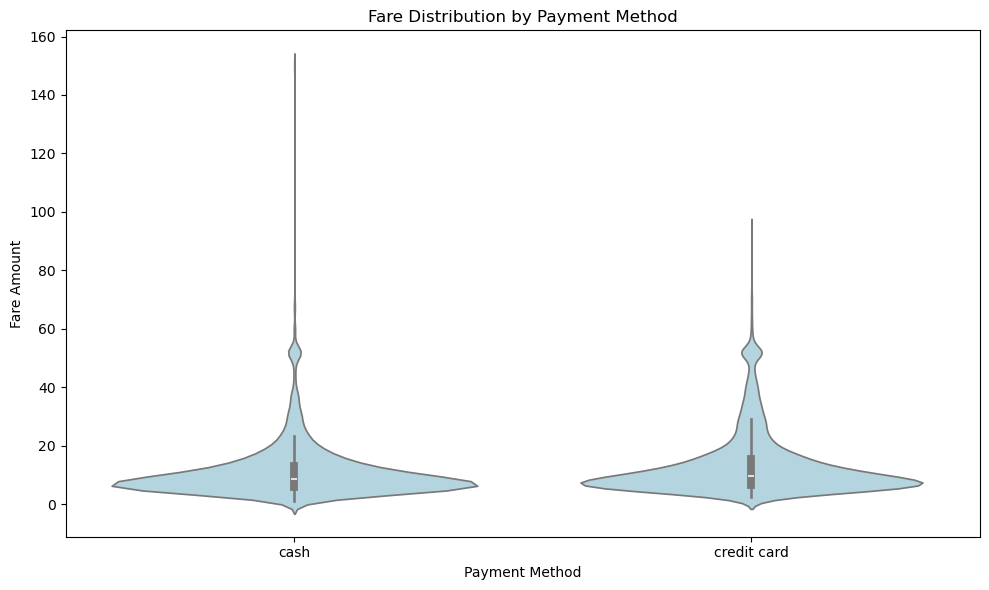

In [38]:
# Violin Plot
plt.figure(figsize=(10, 6))

sns.violinplot(data=df,
               x='payment',
               y='fare',
               color='lightblue')

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.tight_layout()
plt.show()